# Notebook 3 — Clasificación temporal y política de alertas de vuelos (Problema 7)

Datos: `generar_vuelos(n=9600, seed=2026)`, copiada **sin cambios** del notebook de clase
`Taller_clasificacion_vuelos.ipynb`. Etiqueta $Y=\mathbb 1\{\text{min\_retraso}\ge15\}$.
`min_retraso` no se usa como predictor y `fecha_prediccion` solo sirve para ordenar y partir.
La probabilidad interna del generador no se usa (la función ni la devuelve).

Modelo sin ponderar: mi `LogisticRegressionGD`. Modelo ponderado: la misma clase con `class_weight='balanced'`
(lo comparo con scikit-learn más abajo).

**Autor:** Juan José Jiménez Maya.

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, log_loss, brier_score_loss,
                             precision_recall_curve, roc_curve, auc, confusion_matrix,
                             precision_score, recall_score, f1_score, accuracy_score)

from mlcore import LogisticRegressionGD

SEED_DATOS = 2026
GAP = 24
LAMBDAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
C_FP, C_FN = 1.0, 12.0
TAU_TEORICO = C_FP / (C_FP + C_FN)          # umbral de Bayes con costos 1 y 12: 1/13
RECALL_MIN, ALERTAS_MAX = 0.80, 0.15
RES = Path("resultados")
RES.mkdir(exist_ok=True)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
T0 = time.time()
print("Python", sys.version.split()[0])
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Python 3.14.7
numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1


In [2]:
# ---- Copia literal de la celda del notebook de clase (no cambio el mecanismo;
# ---- el seed siempre se pasa explícito, así que el valor por defecto 42 no se usa).
SEED = 42
def generar_vuelos(n=9600, seed=SEED):
    rng = np.random.default_rng(seed)
    fecha = pd.date_range('2024-01-01', periods=n, freq='h')
    hora = ((fecha + pd.Timedelta(hours=2)).hour).to_numpy()
    progreso = np.linspace(0, 1, n)
    aerolinea = rng.choice(['Aero_A', 'Aero_B', 'Aero_C'], n, p=[0.50, 0.30, 0.20])
    origen = rng.choice(['BOG', 'MDE', 'CLO', 'CTG'], n)
    distancia = rng.uniform(200, 1800, n)
    lluvia = rng.gamma(shape=1.2, scale=2.0, size=n)
    viento = np.clip(rng.normal(15, 6, n), 0, 45)
    ocupacion = np.clip(rng.normal(77, 12, n), 25, 100)
    trafico = np.clip(rng.normal(45 + 10 * progreso, 13, n), 5, 100)
    # Probabilidad del simulador: combina factores conocidos antes de la salida.
    logit = (
        -5.3 + 1.1 * (trafico - 45) / 13
        + 0.8 * (lluvia - 2.4) / 2.2 + 0.7 * (viento - 15) / 6
        + 0.35 * (ocupacion - 77) / 12 + 0.55 * (hora >= 17)
        + 0.40 * (origen == 'BOG') + 0.45 * (aerolinea == 'Aero_C')
    )
    probabilidad_generadora = 1 / (1 + np.exp(-logit))
    # La etiqueta se sortea: vuelos similares pueden tener resultados distintos.
    positivo = rng.binomial(1, probabilidad_generadora)
    retraso = np.where(positivo == 1, rng.integers(15, 181, n), rng.integers(-10, 15, n))
    datos = pd.DataFrame({
        'fecha_prediccion': fecha, 'hora_salida': hora,
        'distancia_km': distancia, 'lluvia_pronosticada_mm': lluvia,
        'viento_pronosticado_kmh': viento, 'ocupacion_programada_pct': ocupacion,
        'trafico_programado': trafico, 'aerolinea': aerolinea,
        'origen': origen, 'min_retraso': retraso,
    })
    # Los faltantes afectan a predictores, nunca a la etiqueta observada.
    for columna in ['lluvia_pronosticada_mm', 'viento_pronosticado_kmh',
                    'ocupacion_programada_pct', 'aerolinea']:
        datos.loc[rng.random(n) < 0.06, columna] = np.nan
    return datos

df = generar_vuelos(n=9600, seed=SEED_DATOS)
NUMERICAS = ['hora_salida', 'distancia_km', 'lluvia_pronosticada_mm',
             'viento_pronosticado_kmh', 'ocupacion_programada_pct', 'trafico_programado']
CATEGORICAS = ['aerolinea', 'origen']
FEATURES = NUMERICAS + CATEGORICAS
print(df.shape)

(9600, 10)


## 7a — Diccionario de variables (¿qué se sabe dos horas antes de la salida?)

| Variable | Tipo | Rol | ¿Disponible 2 h antes? | Justificación |
|---|---|---|---|---|
| `fecha_prediccion` | fecha-hora | ordenar y partir | sí | momento en que se hace la predicción; no entra al modelo |
| `hora_salida` | entero 0–23 | predictor | sí | hora programada = fecha de predicción + 2 h |
| `distancia_km` | real | predictor | sí | dato de la ruta |
| `lluvia_pronosticada_mm` | real, con faltantes | predictor | sí | es un **pronóstico**, no la lluvia que cayó |
| `viento_pronosticado_kmh` | real, con faltantes | predictor | sí | pronóstico |
| `ocupacion_programada_pct` | real, con faltantes | predictor | sí | reservas conocidas al predecir |
| `trafico_programado` | real | predictor | sí | tráfico planeado |
| `aerolinea` | categórica, con faltantes | predictor | sí | operador del vuelo |
| `origen` | categórica | predictor | sí | aeropuerto de salida |
| `min_retraso` | entero | **solo etiqueta** | **no** | se conoce después de la salida; usarlo sería fuga |

Partición del notebook de clase: orden cronológico, cortes al 60 % y 80 %, y se quitan las 24 filas anteriores a cada
corte (una fila = una hora; supongo que la etiqueta se conoce en menos de un día).

In [3]:
datos = df.sort_values("fecha_prediccion", kind="stable").reset_index(drop=True)
datos.insert(0, "id_vuelo", [f"V{i:05d}" for i in range(len(datos))])
datos["retrasado"] = (datos["min_retraso"] >= 15).astype(int)
n = len(datos)
c1, c2 = int(n * 0.60), int(n * 0.80)
train = datos.iloc[:c1 - GAP].copy()
valid = datos.iloc[c1:c2 - GAP].copy()
test = datos.iloc[c2:].copy()                      # no se toca hasta 7e

asignacion = pd.Series("excluida_gap", index=datos.index)
asignacion[train.index] = "entrenamiento"
asignacion[valid.index] = "validacion"
asignacion[test.index] = "prueba"
datos[["id_vuelo", "fecha_prediccion"]].assign(particion=asignacion.values).to_csv(RES / "p7_particiones.csv", index=False)

conjuntos = [("entrenamiento", train), ("gap 1 (excluido)", datos.iloc[c1 - GAP:c1]),
             ("validación", valid), ("gap 2 (excluido)", datos.iloc[c2 - GAP:c2]),
             ("prueba (reservada)", test)]
rangos = []
for nombre, p in conjuntos:
    rangos.append({"conjunto": nombre, "filas": len(p), "id_inicio": p.id_vuelo.iloc[0], "id_fin": p.id_vuelo.iloc[-1],
                   "fecha_inicio": p.fecha_prediccion.min(), "fecha_fin": p.fecha_prediccion.max()})
display(pd.DataFrame(rangos))
# comprobaciones de separación temporal
assert datos.fecha_prediccion.is_monotonic_increasing
assert (valid.fecha_prediccion.min() - train.fecha_prediccion.max()) == pd.Timedelta(hours=GAP + 1)
assert (test.fecha_prediccion.min() - valid.fecha_prediccion.max()) == pd.Timedelta(hours=GAP + 1)
assert len(set(train.id_vuelo) & set(valid.id_vuelo)) == 0
assert len(set(valid.id_vuelo) & set(test.id_vuelo)) == 0
assert not {"min_retraso", "retrasado", "fecha_prediccion"} & set(FEATURES)
print("Separación: entre el último vuelo de un conjunto y el primero del siguiente hay", GAP + 1, "horas (24 filas excluidas).")

,conjunto,filas,id_inicio,id_fin,fecha_inicio,fecha_fin
0,entrenamiento,5736,V00000,V05735,2024-01-01,2024-08-26 23:00:00
1,gap 1 (excluido),24,V05736,V05759,2024-08-27,2024-08-27 23:00:00
2,validación,1896,V05760,V07655,2024-08-28,2024-11-14 23:00:00
3,gap 2 (excluido),24,V07656,V07679,2024-11-15,2024-11-15 23:00:00
4,prueba (reservada),1920,V07680,V09599,2024-11-16,2025-02-03 23:00:00


Separación: entre el último vuelo de un conjunto y el primero del siguiente hay 25 horas (24 filas excluidas).


,dtype,faltantes,% faltante,únicos
hora_salida,int32,0,0.0000,24
distancia_km,float64,0,0.0000,5736
lluvia_pronosticada_mm,float64,359,6.2587,5377
viento_pronosticado_kmh,float64,373,6.5028,5332
ocupacion_programada_pct,float64,371,6.4679,5225
trafico_programado,float64,0,0.0000,5732
aerolinea,str,335,5.8403,3
origen,str,0,0.0000,4


,count,mean,std,min,25%,50%,75%,max,asimetría
hora_salida,5736.0,11.5000,6.9228,0.0000,5.7500,11.5000,17.2500,23.0000,0.0000
distancia_km,5736.0,993.0133,456.5584,200.3045,602.8332,992.8272,1382.3332,1799.8927,0.0211
lluvia_pronosticada_mm,5377.0,2.4001,2.1733,0.0010,0.8104,1.7704,3.3192,24.0923,1.8230
viento_pronosticado_kmh,5363.0,14.9766,6.0614,0.0000,10.7751,14.9935,19.2437,37.4953,0.0529
ocupacion_programada_pct,5365.0,77.0179,11.8173,33.3943,69.0296,77.2988,85.0968,100.0000,-0.1856
trafico_programado,5736.0,48.1742,12.9752,5.0000,39.6731,48.2107,56.9148,96.0529,-0.0429


,filas
aerolinea,
Aero_A,2630
Aero_B,1679
Aero_C,1092
NaN,335


,filas
origen,
CTG,1475
CLO,1462
MDE,1417
BOG,1382


Prevalencia en entrenamiento: 0.0244 (140 retrasos de 5736)


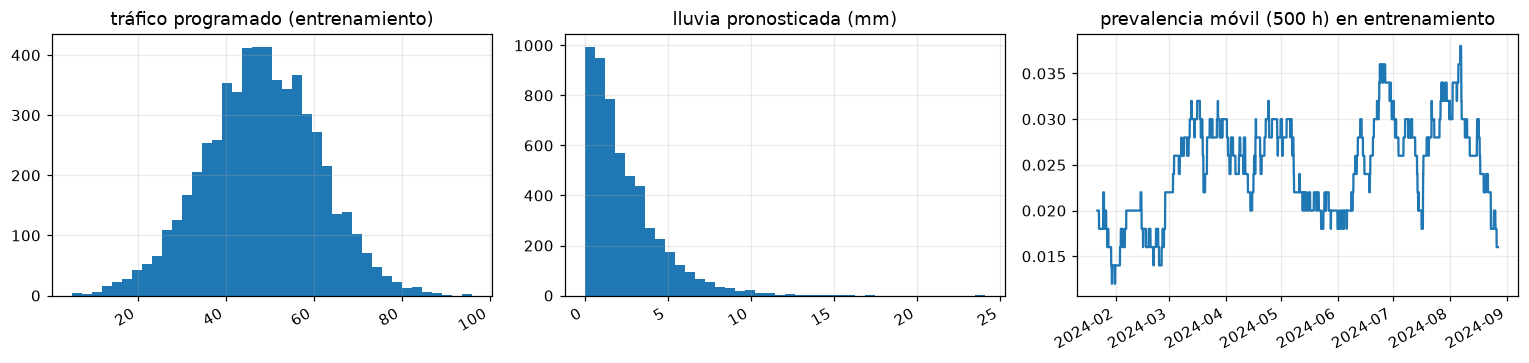

In [4]:
# Auditoría SOLO con entrenamiento
X_tr, y_tr = train[FEATURES], train.retrasado.to_numpy()
X_va, y_va = valid[FEATURES], valid.retrasado.to_numpy()
aud = pd.DataFrame({"dtype": X_tr.dtypes.astype(str), "faltantes": X_tr.isna().sum(),
                    "% faltante": 100 * X_tr.isna().mean(), "únicos": X_tr.nunique()})
display(aud)
display(X_tr[NUMERICAS].describe().T.assign(asimetría=X_tr[NUMERICAS].skew()))
for c in CATEGORICAS:
    display(X_tr[c].value_counts(dropna=False).to_frame("filas"))
print(f"Prevalencia en entrenamiento: {y_tr.mean():.4f} ({y_tr.sum()} retrasos de {len(y_tr)})")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].hist(X_tr.trafico_programado, bins=40)
axes[0].set(title="tráfico programado (entrenamiento)")
axes[1].hist(X_tr.lluvia_pronosticada_mm.dropna(), bins=40)
axes[1].set(title="lluvia pronosticada (mm)")
prevalencia_movil = pd.Series(y_tr).rolling(500).mean()
axes[2].plot(train.fecha_prediccion, prevalencia_movil)
axes[2].set(title="prevalencia móvil (500 h) en entrenamiento")
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(RES / "p7_auditoria.png", bbox_inches="tight")
plt.show()

**Auditoría.** Entrenamiento: 5736 vuelos, 140 retrasos (2.44 %). Hay ≈6 % de faltantes en lluvia, viento, ocupación y
aerolínea (ninguno en la etiqueta). La lluvia es asimétrica y el tráfico programado sube con el tiempo, así que la
prevalencia también sube: validación y prueba pueden tener más retrasos que entrenamiento. Por eso la partición debe
ser temporal.

## Preprocesamiento y modelos
Se ajusta **dentro de cada entrenamiento** (pliegue o entrenamiento completo): numéricas → mediana + estandarización;
categóricas → moda + one-hot con `handle_unknown='ignore'` (una categoría nueva queda como ceros; un faltante se imputa).
El modelo recibe la matriz ya transformada.

In [5]:
def crear_prep():
    numericas = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    categoricas = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", numericas, NUMERICAS), ("cat", categoricas, CATEGORICAS)], remainder="drop")


def crear_modelo(ponderado, lam2):
    if ponderado:
        pesos = "balanced"
    else:
        pesos = None
    return LogisticRegressionGD(lam2=lam2, class_weight=pesos, accelerate=True, tol=1e-8, max_iter=200_000)


def ajustar(ponderado, lam2, X, y, prep=None):
    """Ajusta el preprocesamiento (si no me lo dan) y el modelo con X, y."""
    if prep is None:
        prep = crear_prep().fit(X)
    with warnings.catch_warnings():
        warnings.simplefilter("error", RuntimeWarning)     # si no converge, error
        m = crear_modelo(ponderado, lam2).fit(prep.transform(X), y)
    return prep, m


def probas(prep, m, X):
    return m.predict_proba(prep.transform(X))[:, 1]


# prueba rápida: una categoría nueva y un faltante no rompen el modelo
prep0, m0 = ajustar(False, 0.01, X_tr, y_tr)
raro = X_tr.iloc[[0]].copy()
raro["aerolinea"] = "Aero_NUEVA"
raro["lluvia_pronosticada_mm"] = np.nan
print("p con categoría nueva + faltante:", probas(prep0, m0, raro).round(4))

p con categoría nueva + faltante: [0.0026]


### Equivalencia del modelo ponderado con scikit-learn
Mi objetivo: $\frac{1}{S}\sum_n a_{y_n}\ell_n+\frac{\lambda_2}{2}\lVert w\rVert^2$ con $a_c=N/(2N_c)$ calculado en cada
entrenamiento. La suma de pesos da $S=N_0\frac{N}{2N_0}+N_1\frac{N}{2N_1}=N$.
scikit-learn (`class_weight='balanced'` usa exactamente $N/(2N_c)$) minimiza $C\sum_na_{y_n}\ell_n+\frac12\lVert w\rVert^2$
sin penalizar el intercepto; si multiplico mi objetivo por $1/(N\lambda_2)$ queda igual con $C=1/(N\lambda_2)$.

In [6]:
Xt = prep0.transform(X_tr)
eq = []
for lam in [1e-2, 1.0]:
    for pond in [False, True]:
        mio = crear_modelo(pond, lam).fit(Xt, y_tr)
        sk = LogisticRegression(C=1 / (len(y_tr) * lam), class_weight="balanced" if pond else None,
                                tol=1e-12, max_iter=20_000).fit(Xt, y_tr)
        p_mio = mio.predict_proba(Xt)[:, 1]
        p_sk = sk.predict_proba(Xt)[:, 1]
        theta_sk = np.r_[sk.intercept_, sk.coef_.ravel()]
        F_mio = mio.objective(Xt, y_tr)
        F_sk = mio.objective(Xt, y_tr, theta_sk)
        eq.append({"ponderado": pond, "lambda2": lam, "C": 1 / (len(y_tr) * lam),
                   "error rel. prob.": np.linalg.norm(p_mio - p_sk) / np.linalg.norm(p_sk),
                   "dif. rel. objetivo": abs(F_mio - F_sk) / F_mio,
                   "|b propio - b sk|": abs(mio.intercept_ - sk.intercept_[0])})
eq = pd.DataFrame(eq)
display(eq)
assert (eq["error rel. prob."] < 1e-4).all()

,ponderado,lambda2,C,error rel. prob.,dif. rel. objetivo,|b propio - b sk|
0,False,0.01,0.0174,2.6939e-07,7.5067e-14,1.3548e-06
1,True,0.01,0.0174,1.6014e-07,2.6197e-14,3.7134e-07
2,False,1.00,0.0002,4.0433e-07,1.6676e-14,4.2138e-07
3,True,1.00,0.0002,2.0073e-08,3.4833e-16,4.4408e-08


## 7b — Validación cruzada temporal dentro de entrenamiento
`TimeSeriesSplit(n_splits=4, gap=24)` sobre las filas de entrenamiento en orden (el pliegue de ajuste va creciendo).
Criterio: **AP media** sin ponderar ni remuestrear. Empate (|ΔAP| ≤ 1e-6): prefiero sin ponderar y luego mayor λ2.
Referencias: probabilidad constante igual a la prevalencia del pliegue y la decisión de no alertar nunca.

In [7]:
cortes = list(TimeSeriesSplit(n_splits=4, gap=GAP).split(X_tr))
info_pliegues = []
for k, (i_aj, i_ev) in enumerate(cortes, 1):
    assert i_aj.max() + GAP < i_ev.min()
    assert len(np.unique(y_tr[i_ev])) == 2 and len(np.unique(y_tr[i_aj])) == 2    # ambas clases
    info_pliegues.append({"pliegue": k, "ajuste: filas": len(i_aj), "ajuste: positivos": int(y_tr[i_aj].sum()),
                          "ajuste: id fin": train.id_vuelo.iloc[i_aj[-1]],
                          "evaluación: id inicio": train.id_vuelo.iloc[i_ev[0]], "evaluación: filas": len(i_ev),
                          "evaluación: positivos": int(y_tr[i_ev].sum())})
display(pd.DataFrame(info_pliegues).set_index("pliegue"))


def metricas_prob(y, p):
    return {"AP": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p),
            "log_loss": log_loss(y, p, labels=[0, 1]), "Brier": brier_score_loss(y, p)}


filas = []
for k, (i_aj, i_ev) in enumerate(cortes, 1):
    Xf, yf = X_tr.iloc[i_aj], y_tr[i_aj]
    Xe, ye = X_tr.iloc[i_ev], y_tr[i_ev]
    prep = crear_prep().fit(Xf)                     # preprocesamiento propio del pliegue
    for pond in [False, True]:
        for lam in LAMBDAS:
            _, m = ajustar(pond, lam, Xf, yf, prep)
            nombre = "LR ponderada" if pond else "LR sin ponderar"
            filas.append({"modelo": nombre, "ponderado": pond, "lambda2": lam, "pliegue": k,
                          "iteraciones": m.n_iter_, **metricas_prob(ye, probas(prep, m, Xe))})
    filas.append({"modelo": "Constante = prevalencia", "ponderado": False, "lambda2": np.nan, "pliegue": k,
                  **metricas_prob(ye, np.full(len(ye), yf.mean()))})
    filas.append({"modelo": "No alertar (decisión)", "ponderado": False, "lambda2": np.nan, "pliegue": k,
                  "AP": np.nan, "recall": 0.0, "costo_por_vuelo": C_FN * ye.mean()})
cv = pd.DataFrame(filas)
cv.to_csv(RES / "p7_cv_por_pliegue.csv", index=False)
res_cv = (cv.groupby(["modelo", "ponderado", "lambda2"], dropna=False, sort=False)
            .agg(AP_media=("AP", "mean"), AP_sd=("AP", "std"), ROC_AUC=("ROC_AUC", "mean"),
                 log_loss=("log_loss", "mean"), Brier=("Brier", "mean"), costo_por_vuelo=("costo_por_vuelo", "mean"))
            .reset_index())
res_cv.to_csv(RES / "p7_cv_resumen.csv", index=False)
display(res_cv)
display(cv.pivot_table(index=["modelo", "lambda2"], columns="pliegue", values="AP").round(4))

,ajuste: filas,ajuste: positivos,ajuste: id fin,evaluación: id inicio,evaluación: filas,evaluación: positivos
pliegue,,,,,,
1,1124,22,V01123,V01148,1147,31
2,2271,53,V02270,V02295,1147,27
3,3418,80,V03417,V03442,1147,31
4,4565,110,V04564,V04589,1147,29


,modelo,ponderado,lambda2,AP_media,AP_sd,ROC_AUC,log_loss,Brier,costo_por_vuelo
0,LR sin ponderar,False,0.001,0.2293,0.0643,0.8526,0.0946,0.0225,NaN
1,LR sin ponderar,False,0.010,0.2357,0.0825,0.8561,0.0955,0.0227,NaN
2,LR sin ponderar,False,0.100,0.2157,0.0765,0.8440,0.1095,0.0245,NaN
3,LR sin ponderar,False,1.000,0.2090,0.0807,0.8416,0.1185,0.0250,NaN
4,LR sin ponderar,False,10.000,0.2088,0.0802,0.8415,0.1197,0.0251,NaN
5,LR ponderada,True,0.001,0.2264,0.0719,0.8447,0.4712,0.1528,NaN
6,LR ponderada,True,0.010,0.2379,0.0815,0.8501,0.4624,0.1513,NaN
7,LR ponderada,True,0.100,0.2465,0.0998,0.8565,0.4839,0.1570,NaN
8,LR ponderada,True,1.000,0.2234,0.0869,0.8524,0.5928,0.2008,NaN
9,LR ponderada,True,10.000,0.2107,0.0810,0.8436,0.6760,0.2414,NaN


pliegue                       1       2       3       4
modelo          lambda2                                
LR ponderada    0.001    0.3263  0.1936  0.1597  0.2258
                0.010    0.3581  0.1969  0.1799  0.2169
                0.100    0.3956  0.1892  0.1920  0.2091
                1.000    0.3510  0.1829  0.2018  0.1581
                10.000   0.3271  0.1693  0.2017  0.1447
LR sin ponderar 0.001    0.3199  0.1993  0.1722  0.2259
                0.010    0.3581  0.1805  0.1943  0.2097
                0.100    0.3275  0.1706  0.2022  0.1625
                1.000    0.3245  0.1662  0.2020  0.1433
                10.000   0.3235  0.1662  0.2020  0.1434

Todos los pliegues evaluados tienen las dos clases (27–31 positivos de 1147). El primer pliegue se ajusta con solo
22 positivos.

In [8]:
candidatos = res_cv[res_cv.modelo.str.startswith("LR")].copy()
mejor = candidatos.AP_media.max()
empatados = candidatos[mejor - candidatos.AP_media <= 1e-6].copy()
empatados = empatados.sort_values(["ponderado", "lambda2"], ascending=[True, False])   # sin ponderar y mayor lambda primero
ganador = empatados.iloc[0]
mejor_por_familia = {}
for pond in [False, True]:
    familia = candidatos[candidatos.ponderado == pond]
    mejor_por_familia[pond] = familia.sort_values(["AP_media", "lambda2"], ascending=[False, False]).iloc[0]
historial = {
    "criterio": "max AP media en 4 pliegues TimeSeriesSplit(gap=24); empate <=1e-6: sin ponderar, mayor lambda2",
    "ganador": {"modelo": ganador.modelo, "lambda2": float(ganador.lambda2), "AP_media": float(ganador.AP_media)},
    "candidatos_empatados": int(len(empatados)),
    "mejor_sin_ponderar": {"lambda2": float(mejor_por_familia[False].lambda2), "AP_media": float(mejor_por_familia[False].AP_media)},
    "mejor_ponderado": {"lambda2": float(mejor_por_familia[True].lambda2), "AP_media": float(mejor_por_familia[True].AP_media)},
    "referencia_constante_AP_media": float(res_cv.loc[res_cv.modelo == "Constante = prevalencia", "AP_media"].iloc[0]),
}
with open(RES / "p7_historial_seleccion.json", "w", encoding="utf-8") as f:
    json.dump(historial, f, indent=2, ensure_ascii=False)
print(json.dumps(historial, indent=2, ensure_ascii=False))
GAN_POND = bool(ganador.ponderado)
GAN_LAM = float(ganador.lambda2)

{
  "criterio": "max AP media en 4 pliegues TimeSeriesSplit(gap=24); empate <=1e-6: sin ponderar, mayor lambda2",
  "ganador": {
    "modelo": "LR ponderada",
    "lambda2": 0.1,
    "AP_media": 0.2464645819335814
  },
  "candidatos_empatados": 1,
  "mejor_sin_ponderar": {
    "lambda2": 0.01,
    "AP_media": 0.235650669560666
  },
  "mejor_ponderado": {
    "lambda2": 0.1,
    "AP_media": 0.2464645819335814
  },
  "referencia_constante_AP_media": 0.025719267654751528
}


**Selección.** La mejor AP media es la de la logística ponderada con λ2 = 0.1 (0.2465), frente a 0.2357 de la mejor sin
ponderar (λ2 = 0.01). No hay empate dentro de 1e-6, así que la regla elige el modelo **ponderado, λ2 = 0.1**. La
diferencia (0.011) es pequeña frente a la dispersión entre pliegues (≈0.08–0.10): es una elección por regla, no una
superioridad demostrada. Los dos superan de lejos la referencia constante (AP ≈ 0.026). La ponderación empeora mucho la
log-loss y el Brier: cambia la escala de las probabilidades aunque el orden (AP, ROC-AUC) sea parecido.

## 7c — Contraexperimento de fuga (solo en entrenamiento)
Modelo, λ2 y pliegues fijos (los del ganador). **Contaminado:** ajusto el preprocesamiento una sola vez con todo el
entrenamiento antes de la CV, así cada pliegue usa estadísticas de su "futuro". **Correcto:** lo reajusto en cada pliegue.
Estos resultados no se usan para elegir nada.

In [9]:
prep_global = crear_prep().fit(X_tr)          # ve todo el entrenamiento: contaminado a propósito
fuga = []
for k, (i_aj, i_ev) in enumerate(cortes, 1):
    Xf, yf = X_tr.iloc[i_aj], y_tr[i_aj]
    Xe, ye = X_tr.iloc[i_ev], y_tr[i_ev]
    prep_c, mod_c = ajustar(GAN_POND, GAN_LAM, Xf, yf, prep_global)   # contaminado
    prep_b, mod_b = ajustar(GAN_POND, GAN_LAM, Xf, yf)                # correcto
    a = metricas_prob(ye, probas(prep_c, mod_c, Xe))
    b = metricas_prob(ye, probas(prep_b, mod_b, Xe))
    num_c = prep_c.named_transformers_["num"]
    num_b = prep_b.named_transformers_["num"]
    fuga.append({"pliegue": k, "AP contaminada": a["AP"], "AP correcta": b["AP"], "ΔAP (cont - corr)": a["AP"] - b["AP"],
                 "log-loss contaminada": a["log_loss"], "log-loss correcta": b["log_loss"],
                 "Δlog-loss (cont - corr)": a["log_loss"] - b["log_loss"],
                 "mediana tráfico usada (cont.)": num_c["imputar"].statistics_[5],
                 "mediana tráfico usada (corr.)": num_b["imputar"].statistics_[5],
                 "media tráfico escalador (cont.)": num_c["escalar"].mean_[5],
                 "media tráfico escalador (corr.)": num_b["escalar"].mean_[5]})
fuga = pd.DataFrame(fuga).set_index("pliegue")
fuga.to_csv(RES / "p7_contraexperimento_fuga.csv")
display(fuga)
display(fuga[["ΔAP (cont - corr)", "Δlog-loss (cont - corr)"]].agg(["mean", "min", "max"]))

,AP contaminada,AP correcta,ΔAP (cont - corr),log-loss contaminada,log-loss correcta,Δlog-loss (cont - corr),mediana tráfico usada (cont.),mediana tráfico usada (corr.),media tráfico escalador (cont.),media tráfico escalador (corr.)
pliegue,,,,,,,,,,
1,0.3907,0.3956,-0.0049,0.4366,0.4388,-2.1589e-03,48.2107,46.1814,48.1742,45.7848
2,0.1858,0.1892,-0.0034,0.4684,0.4691,-7.0342e-04,48.2107,46.5362,48.1742,46.3863
3,0.1922,0.1920,0.0002,0.4777,0.4781,-4.0012e-04,48.2107,46.8183,48.1742,46.8841
4,0.2090,0.2091,-0.0001,0.5496,0.5497,-6.1479e-05,48.2107,47.4281,48.1742,47.4456


,ΔAP (cont - corr),Δlog-loss (cont - corr)
mean,-0.0020,-8.3099e-04
min,-0.0049,-2.1589e-03
max,0.0002,-6.1479e-05


**Interpretación.** El procedimiento contaminado usa en cada pliegue estadísticas del futuro (por ejemplo, mediana de
tráfico 48.21 en vez de 46.18–47.43, porque el tráfico crece con el tiempo). Aun así, la AP contaminada sale en promedio
un poco *menor* (ΔAP ≈ −0.002). **El signo y el tamaño de la diferencia no dicen si hay fuga:** la fuga es un error del
procedimiento (usar información que no se tendría al predecir), no del resultado. Aquí lo que se filtra (medias y
medianas) predice poco, y con la deriva temporal puede ayudar o empeorar según el pliegue. Con otra variable la misma
fuga podría inflar mucho la métrica.

### Diagnóstico en validación de los dos candidatos finales (ajustados solo con entrenamiento)

,AP,ROC_AUC,log_loss,Brier,PR-AUC trapezoidal,p media,p mín,p máx
modelo,,,,,,,,
LR sin ponderar (λ2=0.01),0.3915,0.8512,0.1259,0.0316,0.3891,0.0302,0.0008,0.8147
LR ponderada (λ2=0.1),0.3939,0.8528,0.5351,0.1784,0.3917,0.3916,0.0281,0.9889


Prevalencia de validación (para leer AP): 0.039


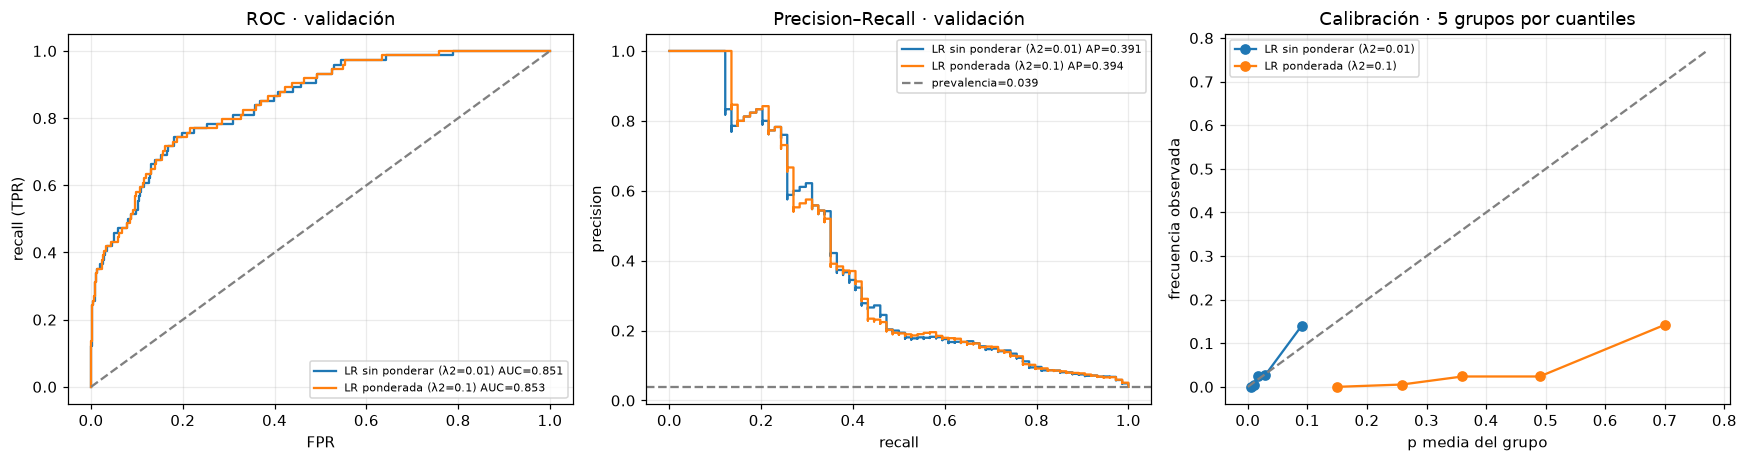

casos  positivos  p_media  frecuencia_obs   p_min   p_max  grupos efectivos por valor  probabilidades repetidas
                          grupo                                                                                                                 
LR sin ponderar (λ2=0.01) 0        380          0   0.0051          0.0000  0.0008  0.0077                           5                         0
                          1        379          2   0.0101          0.0053  0.0077  0.0127                           5                         0
                          2        379          9   0.0166          0.0237  0.0127  0.0214                           5                         0
                          3        379         10   0.0290          0.0264  0.0215  0.0400                           5                         0
                          4        379         53   0.0902          0.1398  0.0400  0.8147                           5                         0
LR ponderada (λ2=0.1)     0        380          0   0.1501          0.0000  0.0281  0.2091                           5                         0
                          1        379          2   0.2582          0.0053  0.2096  0.3045                           5                         0
                          2        379          9   0.3602          0.0237  0.3053  0.4199                           5                         0
                          3        379          9   0.4899          0.0237  0.4202  0.5702                           5                         0
                          4        379         54   0.7003          0.1425  0.5716  0.9889                           5                         0

In [10]:
finales = {}
for pond in [False, True]:
    lam = float(mejor_por_familia[pond].lambda2)
    nombre = f"{'LR ponderada' if pond else 'LR sin ponderar'} (λ2={lam:g})"
    prep, m = ajustar(pond, lam, X_tr, y_tr)
    finales[nombre] = {"ponderado": pond, "lambda2": lam, "prep": prep, "modelo": m, "p_valid": probas(prep, m, X_va)}
for nombre, d in finales.items():
    if d["ponderado"] == GAN_POND and d["lambda2"] == GAN_LAM:
        nombre_ganador = nombre

diag = []
for nombre, d in finales.items():
    p = d["p_valid"]
    prec, rec, _ = precision_recall_curve(y_va, p)
    diag.append({"modelo": nombre, **metricas_prob(y_va, p), "PR-AUC trapezoidal": auc(rec, prec),
                 "p media": p.mean(), "p mín": p.min(), "p máx": p.max()})
diag = pd.DataFrame(diag).set_index("modelo")
diag.to_csv(RES / "p7_diagnostico_validacion.csv")
display(diag)
print("Prevalencia de validación (para leer AP):", round(y_va.mean(), 4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for nombre, d in finales.items():
    fpr, tpr, _ = roc_curve(y_va, d["p_valid"])
    axes[0].plot(fpr, tpr, label=f"{nombre} AUC={roc_auc_score(y_va, d['p_valid']):.3f}")
    prec, rec, _ = precision_recall_curve(y_va, d["p_valid"])
    axes[1].step(rec, prec, where="post", label=f"{nombre} AP={average_precision_score(y_va, d['p_valid']):.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="FPR", ylabel="recall (TPR)", title="ROC · validación")
axes[1].axhline(y_va.mean(), ls="--", color="gray", label=f"prevalencia={y_va.mean():.3f}")
axes[1].set(xlabel="recall", ylabel="precision", title="Precision–Recall · validación")

# calibración: 5 grupos por cuantiles de la probabilidad
tablas_cal = {}
for nombre, d in finales.items():
    grupo = pd.qcut(pd.Series(d["p_valid"]).rank(method="first"), 5, labels=False)
    grupo_por_valor = pd.qcut(d["p_valid"], 5, labels=False, duplicates="drop")   # grupos efectivos si hay repetidas
    t = pd.DataFrame({"grupo": grupo, "p": d["p_valid"], "y": y_va}).groupby("grupo").agg(
        casos=("y", "size"), positivos=("y", "sum"), p_media=("p", "mean"), frecuencia_obs=("y", "mean"),
        p_min=("p", "min"), p_max=("p", "max"))
    t["grupos efectivos por valor"] = len(np.unique(grupo_por_valor))
    t["probabilidades repetidas"] = len(d["p_valid"]) - len(np.unique(d["p_valid"]))
    tablas_cal[nombre] = t
    axes[2].plot(t.p_media, t.frecuencia_obs, "o-", label=nombre)
mx = max(max(t.p_media.max(), t.frecuencia_obs.max()) for t in tablas_cal.values()) * 1.1
axes[2].plot([0, mx], [0, mx], "--", color="gray")
axes[2].set(xlabel="p media del grupo", ylabel="frecuencia observada", title="Calibración · 5 grupos por cuantiles")
for a in axes:
    a.legend(fontsize=7)
plt.tight_layout()
plt.savefig(RES / "p7_validacion.png", bbox_inches="tight")
plt.show()
cal = pd.concat(tablas_cal)
cal.to_csv(RES / "p7_calibracion_validacion.csv")
display(cal)

**Diagnóstico en validación** (prevalencia 3.9 %, más alta que el 2.4 % de entrenamiento). Los dos candidatos ordenan casi
igual (AP 0.392 vs 0.394, ROC-AUC 0.851 vs 0.853). La **AP** es una suma por escalones $\sum_k(R_k-R_{k-1})P_k$; el
**área trapezoidal** une los puntos con rectas y es un poco más optimista (difieren ≈0.002). En calibración, el modelo
sin ponderar está cerca de la diagonal salvo en el último grupo (0.090 vs 0.140); el ponderado sobreestima siempre
(p media 0.15–0.70 frente a frecuencias 0–0.14): al darle peso ≈40 veces mayor a los retrasos, el modelo "infla" sus
probabilidades. Cada grupo tiene 379–380 casos y no hay probabilidades repetidas. **El ganador de la CV no se cambia.**

## 7d — Tabla de umbrales y política (validación, probabilidades fijas del ganador)
Regla $\hat y=\mathbb 1\{p\ge\tau\}$. Evalúo todos los valores únicos predichos, $\tau=0$ ("alertar a todos") y
$\tau=+\infty$ ("no alertar a nadie"), marcados como modo extremo. Costo $\hat C(\tau)=(12\,FN+FP)/N_{val}$.

**Umbral teórico.** Si $p$ fuera la probabilidad verdadera, alertar cuesta $1\cdot(1-p)$ y no alertar cuesta $12p$.
Conviene alertar cuando $12p\ge 1-p$, o sea $p\ge 1/13\approx0.077$.

Umbrales evaluados: 1898 (incluye 2 extremos) | factibles: 0
Pesos de clase del entrenamiento: {0: np.float64(0.5125089349535382), 1: np.float64(20.485714285714284)} -> 1/13 trasladado a la escala ponderada: 0.7691
Estado de la política: inviabilidad empírica


,tau,modo,TP,FP,FN,TN,recall,precision,tasa_alertas,costo
τ = 0.5,0.5,umbral,57,474,17,1348,0.7703,0.1073,0.2801,0.3576
τ teórico = 1/13,0.0769,umbral,74,1794,0,28,1.0,0.0396,0.9852,0.9462
1/13 en escala q* (solo diagnóstico),0.7691,umbral,30,56,44,1766,0.4054,0.3488,0.0454,0.308
máx recall con alertas ≤ 15%,0.6351,umbral,47,219,27,1603,0.6351,0.1767,0.1403,0.2864
mín alertas con recall ≥ 80%,0.4546,umbral,60,596,14,1226,0.8108,0.0915,0.346,0.403
mín costo sin restricciones (diagnóstico),0.6351,umbral,47,219,27,1603,0.6351,0.1767,0.1403,0.2864


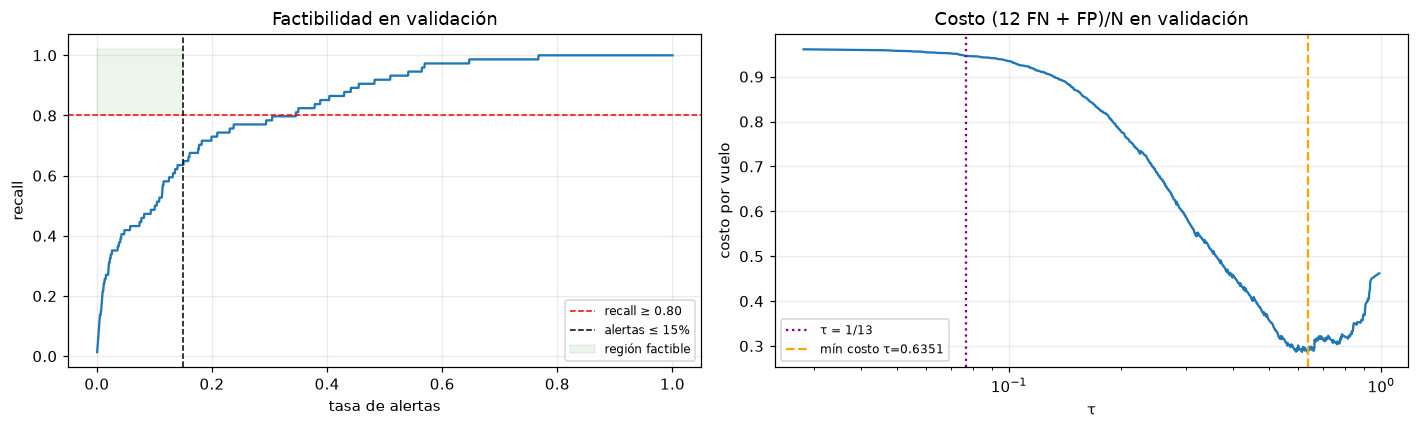

In [11]:
def tabla_umbrales(y, p, taus):
    y = np.asarray(y)
    p = np.asarray(p)
    N = len(y)
    filas = []
    for t in taus:
        pred = p >= t
        tp = int(np.sum(pred & (y == 1)))
        fp = int(np.sum(pred & (y == 0)))
        fn = int(np.sum(~pred & (y == 1)))
        tn = int(np.sum(~pred & (y == 0)))
        if t <= 0:
            modo = "extremo: alertar todos"
        elif np.isinf(t):
            modo = "extremo: no alertar"
        else:
            modo = "umbral"
        filas.append({"tau": t, "modo": modo, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                      "recall": tp / (tp + fn) if tp + fn else 0.0,
                      "precision": tp / (tp + fp) if tp + fp else 0.0,
                      "tasa_alertas": (tp + fp) / N, "costo": (C_FN * fn + C_FP * fp) / N})
    return pd.DataFrame(filas)


p_val = finales[nombre_ganador]["p_valid"]
taus = np.r_[0.0, np.unique(p_val), np.inf]
tu = tabla_umbrales(y_va, p_val, taus)
assert (tu[["TP", "FP", "FN", "TN"]].sum(axis=1) == len(y_va)).all()
assert np.all(np.diff(tu.recall) <= 1e-12) and np.all(np.diff(tu.tasa_alertas) <= 1e-12)
tu["factible"] = (tu.recall >= RECALL_MIN) & (tu.tasa_alertas <= ALERTAS_MAX)
tu.to_csv(RES / "p7_tabla_umbrales_validacion.csv", index=False, float_format="%.17g")
print(f"Umbrales evaluados: {len(tu)} (incluye 2 extremos) | factibles: {int(tu.factible.sum())}")


def fila_tau(t):
    return tabla_umbrales(y_va, p_val, [t]).iloc[0]


factibles = tu[tu.factible]
if len(factibles) > 0:
    politica = factibles.sort_values(["costo", "tasa_alertas", "tau"], ascending=[True, True, False]).iloc[0]
    estado = "factible"
else:
    politica = None
    estado = "inviabilidad empírica"
max_recall_15 = tu[tu.tasa_alertas <= ALERTAS_MAX].sort_values(["recall", "tasa_alertas"], ascending=[False, True]).iloc[0]
min_alertas_80 = tu[tu.recall >= RECALL_MIN].sort_values(["tasa_alertas", "tau"], ascending=[True, False]).iloc[0]
min_costo = tu.sort_values(["costo", "tasa_alertas", "tau"], ascending=[True, True, False]).iloc[0]
# Diagnóstico: el modelo ponderado infla las probabilidades; traslado 1/13 a esa escala con los pesos de entrenamiento
pesos = getattr(finales[nombre_ganador]["modelo"], "class_weights_", None)
if pesos:
    TAU_Q = pesos[1] * TAU_TEORICO / (pesos[1] * TAU_TEORICO + pesos[0] * (1 - TAU_TEORICO))
else:
    TAU_Q = TAU_TEORICO
print(f"Pesos de clase del entrenamiento: {pesos} -> 1/13 trasladado a la escala ponderada: {TAU_Q:.4f}")
columnas_comp = {"τ = 0.5": fila_tau(0.5), "τ teórico = 1/13": fila_tau(TAU_TEORICO),
                 "1/13 en escala q* (solo diagnóstico)": fila_tau(TAU_Q),
                 "máx recall con alertas ≤ 15%": max_recall_15,
                 "mín alertas con recall ≥ 80%": min_alertas_80,
                 "mín costo sin restricciones (diagnóstico)": min_costo}
if politica is not None:
    columnas_comp["política seleccionada"] = politica
comparacion = pd.DataFrame(columnas_comp).T
print("Estado de la política:", estado)
display(comparacion[["tau", "modo", "TP", "FP", "FN", "TN", "recall", "precision", "tasa_alertas", "costo"]])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tt = tu[tu.modo == "umbral"]
ax[0].plot(tt.tasa_alertas, tt.recall, lw=1.5)
ax[0].axhline(RECALL_MIN, color="r", ls="--", lw=1, label="recall ≥ 0.80")
ax[0].axvline(ALERTAS_MAX, color="k", ls="--", lw=1, label="alertas ≤ 15%")
ax[0].fill_between([0, ALERTAS_MAX], RECALL_MIN, 1.02, color="green", alpha=0.08, label="región factible")
ax[0].set(xlabel="tasa de alertas", ylabel="recall", title="Factibilidad en validación")
ax[0].legend(fontsize=8)
ax[1].plot(tt.tau, tt.costo)
ax[1].axvline(TAU_TEORICO, color="purple", ls=":", label="τ = 1/13")
ax[1].axvline(min_costo.tau, color="orange", ls="--", label=f"mín costo τ={min_costo.tau:.4f}")
ax[1].set(xscale="log", xlabel="τ", ylabel="costo por vuelo", title="Costo (12 FN + FP)/N en validación")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(RES / "p7_umbrales.png", bbox_inches="tight")
plt.show()

**Resultado: inviabilidad empírica.** Ninguno de los 1898 umbrales cumple a la vez recall ≥ 0.80 y alertas ≤ 15 % en
validación. Con máximo 15 % de alertas el mejor recall es 0.635 (τ ≈ 0.6351, 14.0 % de alertas); para llegar a recall 0.80
hace falta alertar al menos al 34.6 % (τ ≈ 0.4546). No cambio los límites ni los datos. Dejo congelado como **referencia
diagnóstica (no como política aprobada)** el umbral de menor costo sin restricciones, τ ≈ 0.6351 (costo 0.286 por vuelo).

**Comparación.** τ = 0.5 da recall 0.77 con 28 % de alertas (costo 0.358). El umbral 1/13 supone que $p$ es la
probabilidad verdadera; con las probabilidades **ponderadas** (infladas) alerta al 98.5 % de los vuelos (costo 0.946),
peor que no alertar (≈0.47). Si traslado 1/13 a la escala ponderada con los pesos de entrenamiento, el umbral queda
≈0.769 y cuesta 0.308, cerca del mínimo (0.286): el problema era la escala, no la regla. No lo uso como política
porque ese traslado solo vale si el modelo fuera perfecto.

## 7e — Manifiesto congelado antes de abrir prueba

In [12]:
prep_g = finales[nombre_ganador]["prep"]
mod_g = finales[nombre_ganador]["modelo"]
num_t = prep_g.named_transformers_["num"]
cat_t = prep_g.named_transformers_["cat"]
if politica is not None:
    tau_sel = float(politica.tau)
    clave_tau = "tau_seleccionado"
else:
    tau_sel = float(min_costo.tau)
    clave_tau = "tau_diagnostico_min_costo"
manifiesto = {
    "creado_antes_de_abrir_prueba": True,
    "datos": "generar_vuelos(n=9600, seed=2026); Y = 1{min_retraso >= 15}",
    "particion": {"cortes": [c1, c2], "gap_filas": GAP,
                  "entrenamiento": [train.id_vuelo.iloc[0], train.id_vuelo.iloc[-1]],
                  "validacion": [valid.id_vuelo.iloc[0], valid.id_vuelo.iloc[-1]],
                  "prueba": [test.id_vuelo.iloc[0], test.id_vuelo.iloc[-1]]},
    "variables": {"numericas": NUMERICAS, "categoricas": CATEGORICAS, "excluidas": ["fecha_prediccion", "min_retraso"]},
    "preprocesamiento": {
        "numericas": {"imputacion_mediana": dict(zip(NUMERICAS, num_t["imputar"].statistics_.tolist())),
                      "media": dict(zip(NUMERICAS, num_t["escalar"].mean_.tolist())),
                      "escala": dict(zip(NUMERICAS, num_t["escalar"].scale_.tolist()))},
        "categoricas": {"imputacion_moda": dict(zip(CATEGORICAS, cat_t["imputar"].statistics_.tolist())),
                        "categorias": {c: list(map(str, v)) for c, v in zip(CATEGORICAS, cat_t["onehot"].categories_)},
                        "handle_unknown": "ignore"},
        "ajustado_con": "entrenamiento completo"},
    "modelo": {"clase": "mlcore.LogisticRegressionGD", "ponderado": GAN_POND, "lambda2": GAN_LAM,
               "columnas": prep_g.get_feature_names_out().tolist(),
               "coef": mod_g.coef_.tolist(), "intercept": mod_g.intercept_,
               "iteraciones": mod_g.n_iter_, "terminacion": mod_g.termination_},
    "regla": "alerta si p >= tau",
    "politicas": {"tau_0.5": 0.5, "tau_teorico_1_13": TAU_TEORICO, clave_tau: repr(tau_sel)},
    "estado_politica_validacion": estado,
    "restricciones": {"recall_min": RECALL_MIN, "tasa_alertas_max": ALERTAS_MAX, "C_FP": C_FP, "C_FN": C_FN},
}
with open(RES / "p7_manifiesto_politica.json", "w", encoding="utf-8") as f:
    json.dump(manifiesto, f, indent=2, ensure_ascii=False)
print(f"Manifiesto guardado. τ ({'seleccionado' if politica is not None else 'diagnóstico'}) = {tau_sel!r}")

Manifiesto guardado. τ (diagnóstico) = 0.6351112312464089


### Evaluación única en prueba (sin reentrenar con validación)

In [13]:
with open(RES / "p7_manifiesto_politica.json", encoding="utf-8") as f:
    man = json.load(f)
tau_congelado = float(man["politicas"][clave_tau])         # leo el umbral desde el manifiesto
X_te, y_te = test[FEATURES], test.retrasado.to_numpy()
p_te = probas(prep_g, mod_g, X_te)
if politica is not None:
    nombre_tau = "τ seleccionado"
else:
    nombre_tau = "τ diagnóstico (mín costo val.)"
politicas = {"τ = 0.5": 0.5, "τ teórico = 1/13": TAU_TEORICO, nombre_tau: tau_congelado}
filas = []
for nombre, t in politicas.items():
    pred = (p_te >= t).astype(int)
    # matriz de confusión a mano con NumPy
    tp = int(np.sum((pred == 1) & (y_te == 1)))
    tn = int(np.sum((pred == 0) & (y_te == 0)))
    fp = int(np.sum((pred == 1) & (y_te == 0)))
    fn = int(np.sum((pred == 0) & (y_te == 1)))
    assert np.array_equal(confusion_matrix(y_te, pred, labels=[0, 1]).ravel(), [tn, fp, fn, tp])
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn)
    espec = tn / (tn + fp)
    f1 = 2 * tp / (2 * tp + fp + fn) if tp else 0.0
    acc = (tp + tn) / len(y_te)
    # verifico contra scikit-learn
    np.testing.assert_allclose([prec, rec, f1, acc],
                               [precision_score(y_te, pred, zero_division=0), recall_score(y_te, pred),
                                f1_score(y_te, pred, zero_division=0), accuracy_score(y_te, pred)])
    filas.append({"política": nombre, "tau": t, "TP": tp, "FP": fp, "FN": fn, "TN": tn, "precision": prec, "recall": rec,
                  "especificidad": espec, "F1": f1, "accuracy": acc, **metricas_prob(y_te, p_te),
                  "costo": (C_FN * fn + C_FP * fp) / len(y_te), "alertas_por_1000": 1000 * (tp + fp) / len(y_te),
                  "recall ≥ 0.80": rec >= RECALL_MIN, "alertas ≤ 15%": (tp + fp) / len(y_te) <= ALERTAS_MAX})
final = pd.DataFrame(filas).set_index("política")
for c in ["AP", "ROC_AUC", "log_loss", "Brier"]:
    assert final[c].nunique() == 1, c            # las métricas de probabilidad no dependen del umbral
final.to_csv(RES / "p7_evaluacion_final_prueba.csv")
display(final.T)
print(f"Prueba: {int(y_te.sum())} retrasos de {len(y_te)} (prevalencia {y_te.mean():.4f}) — calculada solo ahora.")

predicciones = pd.DataFrame({"id_vuelo": test.id_vuelo.values, "fecha_prediccion": test.fecha_prediccion.values,
                             "retrasado": y_te, "probabilidad": p_te})
for nombre, t in politicas.items():
    predicciones[f"decision_{nombre}"] = (p_te >= t).astype(int)
predicciones.to_csv(RES / "p7_predicciones_prueba.csv", index=False)
print(f"Tiempo total del notebook: {time.time() - T0:.1f} s")

política,τ = 0.5,τ teórico = 1/13,τ diagnóstico (mín costo val.)
tau,0.5,0.0769,0.6351
TP,57,71,50
FP,565,1821,234
FN,14,0,21
TN,1284,28,1615
precision,0.0916,0.0375,0.1761
recall,0.8028,1.0,0.7042
especificidad,0.6944,0.0151,0.8734
F1,0.1645,0.0723,0.2817
accuracy,0.6984,0.0516,0.8672


Prueba: 71 retrasos de 1920 (prevalencia 0.0370) — calculada solo ahora.
Tiempo total del notebook: 5.2 s


**Reporte final (una sola evaluación, modelo congelado, sin reentrenar con validación).** En prueba (71 retrasos en
1920 vuelos, 3.7 %): AP = 0.409, ROC-AUC = 0.869, log-loss = 0.561 y Brier = 0.191, iguales para las tres políticas
porque solo dependen de las probabilidades (lo compruebo con `assert`). Métricas de decisión, calculadas con NumPy y
verificadas contra scikit-learn:

* **τ = 0.5:** recall 0.80, 324 alertas por 1000 vuelos, costo 0.382. Cumple el recall pero no la capacidad.
* **τ = 1/13:** recall 1.0 con 985 alertas por 1000 (casi alertar a todos), costo 0.948.
* **τ diagnóstico ≈ 0.6351:** recall 0.70, 148 alertas por 1000 (≤ 15 %), costo 0.253, el menor de los tres. Cumple la
  capacidad pero no el recall: igual que en validación, ninguna política cumple las dos cosas.

Cumplir en validación no garantizaba cumplir en prueba: el umbral se eligió con 74 positivos (cada retraso mueve el recall
≈1.4 puntos) y la prevalencia y el tráfico cambian con el tiempo. No ajusto la política después de ver esto; la conclusión
es que con este modelo y estas variables la meta (recall ≥ 0.80 con ≤ 15 % de alertas) no se alcanza.